Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading Excel dataset... this may take a little time for a large workbook.
Loaded online_retail: 541,909 rows x 8 columns

1.1 Sample rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom



1.2 Distinct countries


,Country
0,Australia
1,Austria
2,Bahrain
3,Belgium
4,Brazil
5,Canada
6,Channel Islands
7,Cyprus
8,Czech Republic
9,Denmark



2.1 Higher unit-price rows (inspect, not automatically errors)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
0,C556445,M,Manual,-1,38970.00,United Kingdom
1,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,United Kingdom
2,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,United Kingdom
3,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,United Kingdom
4,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,United Kingdom
5,537632,AMAZONFEE,AMAZON FEE,1,13541.33,United Kingdom
6,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,United Kingdom
7,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,United Kingdom
8,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,United Kingdom
9,A563185,B,Adjust bad debt,1,11062.06,United Kingdom


... (45 outputs left out)

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,calculated_value,CustomerID,Country
0,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,United Kingdom



9.7 Monthly coverage — check final month's last recorded date


,sales_month,last_recorded_datetime,unique_invoice_ids,net_calculated_value
0,2010-12-01,2010-12-23 17:41:00,2025,748957.02
1,2011-01-01,2011-01-31 16:59:00,1476,560000.26
2,2011-02-01,2011-02-28 17:04:00,1393,498062.65
3,2011-03-01,2011-03-31 19:55:00,1983,683267.08
4,2011-04-01,2011-04-28 19:53:00,1744,493207.12
5,2011-05-01,2011-05-31 15:53:00,2162,723333.51
6,2011-06-01,2011-06-30 20:08:00,2012,691123.12
7,2011-07-01,2011-07-31 16:04:00,1927,681300.11
8,2011-08-01,2011-08-31 17:45:00,1737,682680.51
9,2011-09-01,2011-09-30 17:22:00,2327,1019687.62



INTERPRETATION NOTES
• Quantity * UnitPrice is a calculated transaction value, not verified accounting revenue.
• Invoice IDs include cancellation IDs; do not automatically label them completed orders.
• Missing CustomerID rows can be included in transaction totals but not identified-customer analysis.
• Returns, cancellations, zero/negative prices, and anomalous quantities need documented treatment.
• December 2011 is partial in this dataset; its month-over-month decline is not like-for-like.
• StockCode 23843 quantity 80,995 on invoice 581483 is flagged for validation, not declared erroneous.
• Product analysis excludes DOT, M, POST as common service codes; validate that rule before client reporting.
• The SQL analysis is complete as a learning milestone; a client-ready report/dashboard and documented definitions are still needed for a portfolio-ready project.


10. VISUAL ANALYSIS — MATPLOTLIB CHARTS


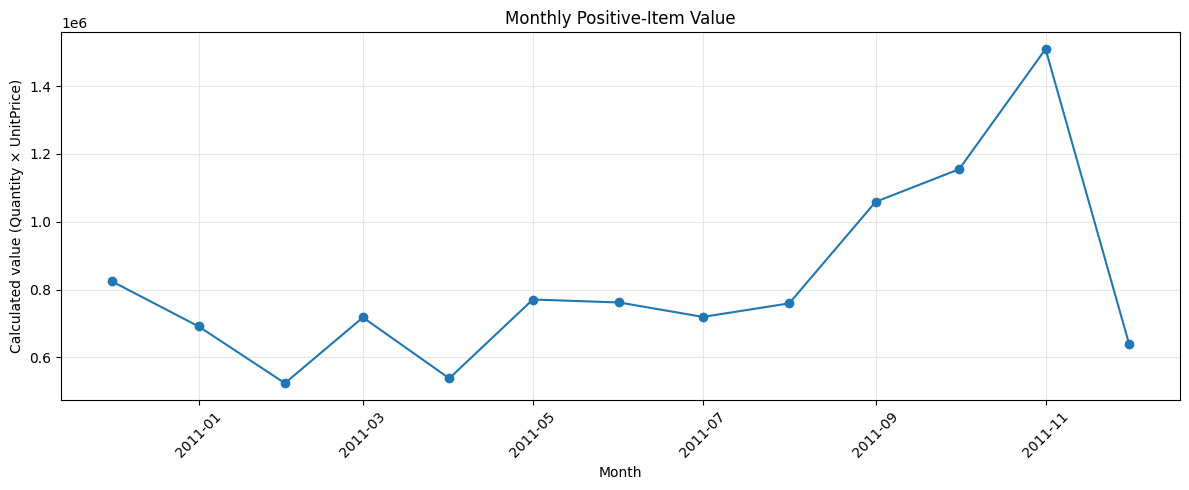

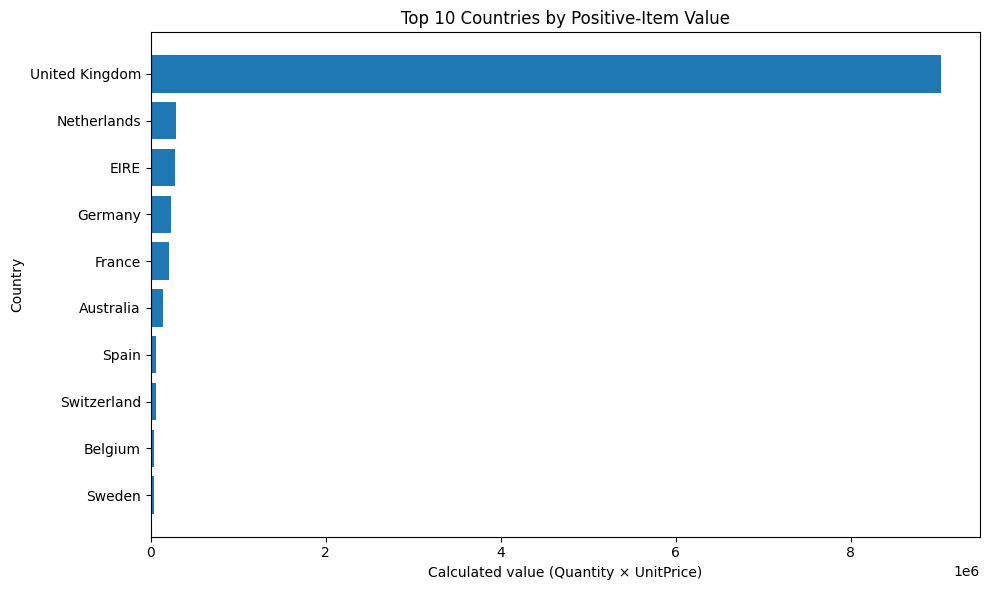

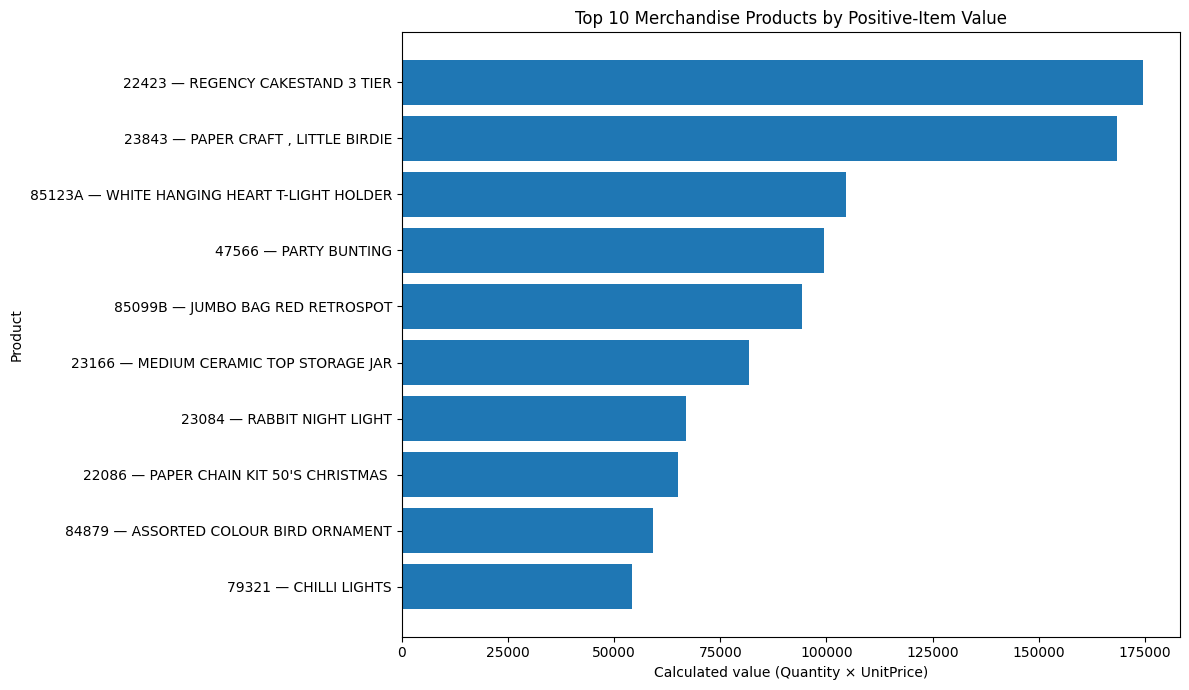

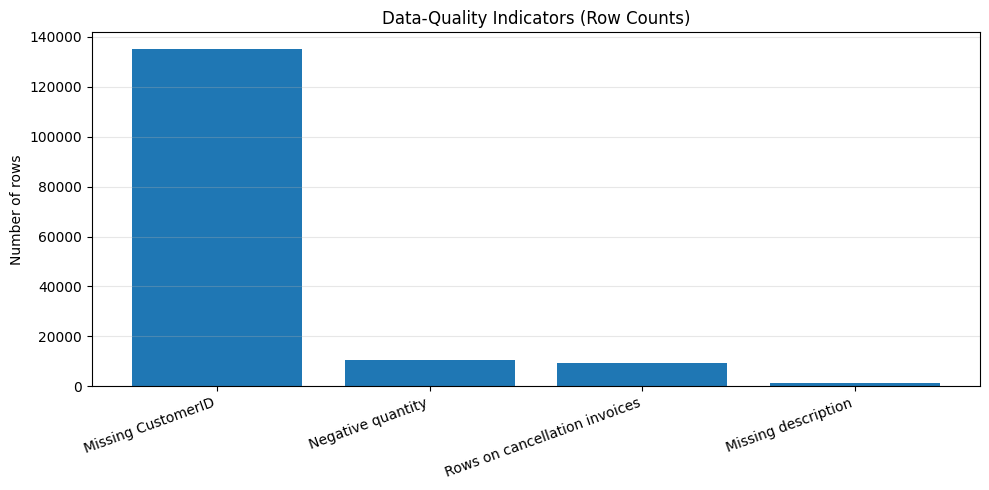


All four Matplotlib charts have been generated.
Reminder: calculated value is Quantity × UnitPrice, not verified accounting revenue.

11. PORTFOLIO EXPORTS AND BUSINESS INSIGHTS
Saved project_kpis.csv (1 rows)
Saved monthly_positive_item_value.csv (13 rows)
Saved country_positive_item_value.csv (38 rows)
Saved product_positive_item_value.csv (3,919 rows)
Saved data_quality_flags.csv (1 rows)

BUSINESS INSIGHTS (generated from this dataset)
1. Top country by positive-item value: United Kingdom (9,025,222.08; 84.6% of country totals).
2. Top merchandise product by positive-item value: StockCode 22423 — REGENCY CAKESTAND 3 TIER (174,484.74).
3. Highest positive-item-value month: November 2011 (1,509,496.33).
4. Rows missing CustomerID: 135,080 (24.93% of all rows); customer-level analysis may be incomplete.
5. Rows with negative quantities: 10,624; investigate as potential returns/adjustments, not automatic errors.

All outputs saved to: /content/drive/MyDrive/Online_Retail_Portfolio_Out

In [3]:
import pandas as pd
import duckdb
from pathlib import Path
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive')

# Portfolio outputs are saved to Drive for reuse in reports / Power BI.
output_dir = Path('/content/drive/MyDrive/Online_Retail_Portfolio_Output')
output_dir.mkdir(parents=True, exist_ok=True)

file_path = '/content/drive/MyDrive/Online Retail.xlsx'

# Fail early with a clear message if the file path/name is wrong.
if not Path(file_path).exists():
    raise FileNotFoundError(
        f"Could not find: {file_path}. Put 'Online Retail.xlsx' directly inside MyDrive, "
        "or update file_path to the correct location."
    )

print('Loading Excel dataset... this may take a little time for a large workbook.')
df = pd.read_excel(file_path, engine='openpyxl')
required_columns = {
    'InvoiceNo', 'StockCode', 'Description', 'Quantity',
    'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country'
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f'Missing expected columns in Excel file: {sorted(missing_columns)}')

# Keep missing values as NULLs in DuckDB and parse dates consistently.
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
con = duckdb.connect(database=':memory:')
con.register('retail_df', df)
con.execute('CREATE TABLE online_retail AS SELECT * FROM retail_df')
con.unregister('retail_df')
print(f"Loaded online_retail: {len(df):,} rows x {len(df.columns)} columns")

def run_query(title, sql):
    print("\n" + "=" * 80 + "\n" + title + "\n" + "=" * 80)
    display(con.execute(sql).df())

# 1 — BASICS
run_query("1.1 Sample rows", """
    SELECT * FROM online_retail LIMIT 10
""")
run_query("1.2 Distinct countries", """
    SELECT DISTINCT Country FROM online_retail ORDER BY Country
""")

# 2 — FILTERS / NULLS
run_query("2.1 Higher unit-price rows (inspect, not automatically errors)", """
    SELECT InvoiceNo, StockCode, Description, Quantity, UnitPrice, Country
    FROM online_retail
    WHERE UnitPrice > 5
    ORDER BY UnitPrice DESC
    LIMIT 20
""")
run_query("2.2 Missing customer IDs", """
    SELECT InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country
    FROM online_retail
    WHERE CustomerID IS NULL
    LIMIT 10
""")
run_query("2.3 Missingness overview", """
    SELECT COUNT(*) AS total_rows,
           COUNT(*) FILTER (WHERE CustomerID IS NULL) AS missing_customer_rows,
           COUNT(*) FILTER (WHERE Description IS NULL) AS missing_description_rows,
           COUNT(*) FILTER (WHERE InvoiceDate IS NULL) AS missing_date_rows
    FROM online_retail
""")

# 3 — AGGREGATES
run_query("3.1 Dataset KPIs", """
    SELECT COUNT(*) AS total_rows,
           COUNT(DISTINCT InvoiceNo) AS unique_invoice_ids,
           COUNT(DISTINCT CustomerID) AS unique_identified_customers,
           COUNT(DISTINCT StockCode) AS unique_stock_codes,
           ROUND(AVG(UnitPrice), 2) AS average_unit_price,
           MIN(UnitPrice) AS minimum_unit_price,
           MAX(UnitPrice) AS maximum_unit_price
    FROM online_retail
""")
run_query("3.2 Net calculated value by country (all rows, includes returns/cancellations)", """
    SELECT Country, ROUND(SUM(Quantity * UnitPrice), 2) AS net_calculated_value
    FROM online_retail
    GROUP BY Country
    ORDER BY net_calculated_value DESC
    LIMIT 10
""")

# 4 — CASE / COALESCE
run_query("4.1 Transaction row categories", """
    SELECT CASE
             WHEN InvoiceNo LIKE 'C%' THEN 'Cancellation invoice'
             WHEN Quantity < 0 THEN 'Negative quantity, non-C invoice'
             WHEN UnitPrice <= 0 THEN 'Non-positive unit price'
             ELSE 'Other rows'
           END AS transaction_category,
           COUNT(*) AS total_rows,
           ROUND(SUM(Quantity * UnitPrice), 2) AS calculated_value
    FROM online_retail
    GROUP BY transaction_category
    ORDER BY transaction_category
""")
run_query("4.2 Positive-item value versus all-row net value", """
    SELECT ROUND(SUM(Quantity * UnitPrice), 2) AS all_rows_net_value,
           ROUND(SUM(CASE WHEN InvoiceNo NOT LIKE 'C%'
                           AND Quantity > 0 AND UnitPrice > 0
                          THEN Quantity * UnitPrice ELSE 0 END), 2)
               AS positive_item_value_excluding_cancellations,
           ROUND(SUM(CASE WHEN InvoiceNo LIKE 'C%'
                          THEN Quantity * UnitPrice ELSE 0 END), 2)
               AS cancellation_invoice_value
    FROM online_retail
""")

# MEASUREMENT DEFINITIONS
# Positive-item value: InvoiceNo not starting with C, Quantity > 0, UnitPrice > 0.
# This is a transaction-value proxy, NOT verified accounting revenue or profit.
# Product analysis additionally excludes service/non-merchandise codes DOT, M, POST.
# Country/month analysis may include those codes; see README for this distinction.
# Validate the service-code exclusion with business stakeholders before client reporting.

# 5 — JOIN, without multiplying sales due to duplicate descriptions
run_query("5.1 Product sales with one representative description per StockCode", """
    WITH product_info AS (
        SELECT StockCode,
               MODE(Description) FILTER (WHERE Description IS NOT NULL) AS Description
        FROM online_retail
        GROUP BY StockCode
    ),
    product_sales AS (
        SELECT StockCode, SUM(Quantity) AS total_quantity,
               COUNT(DISTINCT InvoiceNo) AS unique_invoices,
               SUM(Quantity * UnitPrice) AS calculated_sales
        FROM online_retail
        WHERE InvoiceNo NOT LIKE 'C%'
          AND Quantity > 0 AND UnitPrice > 0
          AND StockCode NOT IN ('DOT', 'M', 'POST')
        GROUP BY StockCode
    )
    SELECT s.StockCode, p.Description, s.total_quantity, s.unique_invoices,
           ROUND(s.calculated_sales, 2) AS calculated_sales
    FROM product_sales s
    LEFT JOIN product_info p USING (StockCode)
    ORDER BY s.calculated_sales DESC, s.StockCode
    LIMIT 10
""")
run_query("5.2 Stock codes with inconsistent descriptions", """
    SELECT StockCode,
           COUNT(DISTINCT Description) AS distinct_description_count,
           LIST(DISTINCT Description) FILTER (WHERE Description IS NOT NULL) AS descriptions
    FROM online_retail
    GROUP BY StockCode
    HAVING COUNT(DISTINCT Description) > 1
    ORDER BY distinct_description_count DESC, StockCode
    LIMIT 20
""")

# 6 — DATES / BUSINESS ANALYSIS
run_query("6.1 Monthly net calculated value (all rows)", """
    SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
           ROUND(SUM(Quantity * UnitPrice), 2) AS net_calculated_value
    FROM online_retail
    WHERE InvoiceDate IS NOT NULL
    GROUP BY sales_month
    ORDER BY sales_month
""")
run_query("6.2 Yearly net calculated value (all rows)", """
    SELECT EXTRACT(YEAR FROM InvoiceDate)::INTEGER AS sales_year,
           ROUND(SUM(Quantity * UnitPrice), 2) AS net_calculated_value
    FROM online_retail
    WHERE InvoiceDate IS NOT NULL
    GROUP BY sales_year
    ORDER BY sales_year
""")
run_query("6.3 Month-over-month change (all-row net value)", """
    WITH monthly AS (
        SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
               SUM(Quantity * UnitPrice) AS net_value
        FROM online_retail
        WHERE InvoiceDate IS NOT NULL
        GROUP BY sales_month
    ),
    compared AS (
        SELECT sales_month, net_value,
               LAG(net_value) OVER (ORDER BY sales_month) AS previous_month_value
        FROM monthly
    )
    SELECT sales_month,
           ROUND(net_value, 2) AS net_calculated_value,
           ROUND(previous_month_value, 2) AS previous_month_value,
           ROUND(100.0 * (net_value - previous_month_value)
                 / NULLIF(previous_month_value, 0), 2) AS mom_change_percent
    FROM compared
    ORDER BY sales_month
""")
run_query("6.4 Monthly positive-item value (filtered measure)", """
    SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
           ROUND(SUM(Quantity * UnitPrice), 2) AS positive_item_value
    FROM online_retail
    WHERE InvoiceDate IS NOT NULL
      AND InvoiceNo NOT LIKE 'C%'
      AND Quantity > 0 AND UnitPrice > 0
    GROUP BY sales_month
    ORDER BY sales_month
""")

# 7 — SUBQUERIES / CTEs
run_query("7.1 Unit prices above the average positive unit price", """
    SELECT StockCode, Description, UnitPrice
    FROM online_retail
    WHERE UnitPrice > (SELECT AVG(UnitPrice) FROM online_retail WHERE UnitPrice > 0)
    ORDER BY UnitPrice DESC
    LIMIT 20
""")
run_query("7.2 Top countries by positive-item value", """
    WITH country_sales AS (
        SELECT Country, COUNT(DISTINCT InvoiceNo) AS unique_invoices,
               SUM(Quantity * UnitPrice) AS calculated_sales
        FROM online_retail
        WHERE InvoiceNo NOT LIKE 'C%'
          AND Quantity > 0 AND UnitPrice > 0
        GROUP BY Country
    )
    SELECT Country, unique_invoices, ROUND(calculated_sales, 2) AS calculated_sales
    FROM country_sales
    ORDER BY calculated_sales DESC
    LIMIT 10
""")

# 8 — WINDOW FUNCTIONS
run_query("8.1 Product rankings — consistent filters and one row per StockCode", """
    WITH product_sales AS (
        SELECT StockCode, SUM(Quantity * UnitPrice) AS calculated_sales
        FROM online_retail
        WHERE InvoiceNo NOT LIKE 'C%'
          AND Quantity > 0 AND UnitPrice > 0
          AND StockCode NOT IN ('DOT', 'M', 'POST')
        GROUP BY StockCode
    )
    SELECT StockCode, ROUND(calculated_sales, 2) AS calculated_sales,
           ROW_NUMBER() OVER (ORDER BY calculated_sales DESC, StockCode) AS row_number,
           RANK() OVER (ORDER BY calculated_sales DESC) AS sales_rank,
           DENSE_RANK() OVER (ORDER BY calculated_sales DESC) AS dense_rank
    FROM product_sales
    ORDER BY calculated_sales DESC, StockCode
    LIMIT 10
""")
run_query("8.2 Monthly running total (all-row net value)", """
    WITH monthly AS (
        SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
               SUM(Quantity * UnitPrice) AS net_value
        FROM online_retail
        WHERE InvoiceDate IS NOT NULL
        GROUP BY sales_month
    )
    SELECT sales_month, ROUND(net_value, 2) AS net_calculated_value,
           ROUND(SUM(net_value) OVER (
               ORDER BY sales_month ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
           ), 2) AS running_net_value
    FROM monthly
    ORDER BY sales_month
""")
run_query("8.3 LAG and LEAD monthly comparison", """
    WITH monthly AS (
        SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
               SUM(Quantity * UnitPrice) AS net_value
        FROM online_retail
        WHERE InvoiceDate IS NOT NULL
        GROUP BY sales_month
    )
    SELECT sales_month, ROUND(net_value, 2) AS net_calculated_value,
           ROUND(LAG(net_value) OVER (ORDER BY sales_month), 2) AS previous_month_value,
           ROUND(LEAD(net_value) OVER (ORDER BY sales_month), 2) AS next_month_value
    FROM monthly
    ORDER BY sales_month
""")

# 9 — PROJECT KPIs / DATA QUALITY / FINDINGS
run_query("9.1 Project KPI overview", """
    SELECT COUNT(*) AS total_rows,
           COUNT(DISTINCT InvoiceNo) AS unique_invoice_ids_including_cancellations,
           COUNT(DISTINCT CustomerID) AS unique_identified_customers,
           COUNT(DISTINCT StockCode) AS unique_stock_codes_including_service_codes,
           ROUND(SUM(Quantity * UnitPrice), 2) AS all_rows_net_calculated_value,
           ROUND(SUM(CASE WHEN InvoiceNo NOT LIKE 'C%'
                           AND Quantity > 0 AND UnitPrice > 0
                          THEN Quantity * UnitPrice ELSE 0 END), 2)
               AS positive_item_value_excluding_cancellations
    FROM online_retail
""")
run_query("9.2 Data-quality flags", """
    SELECT COUNT(*) AS total_rows,
           COUNT(*) FILTER (WHERE CustomerID IS NULL) AS missing_customer_rows,
           ROUND(100.0 * COUNT(*) FILTER (WHERE CustomerID IS NULL) / COUNT(*), 2)
               AS missing_customer_percent,
           COUNT(*) FILTER (WHERE Quantity < 0) AS negative_quantity_rows,
           COUNT(*) FILTER (WHERE UnitPrice < 0) AS negative_unit_price_rows,
           COUNT(*) FILTER (WHERE UnitPrice = 0) AS zero_unit_price_rows,
           COUNT(*) FILTER (WHERE InvoiceNo LIKE 'C%') AS rows_on_cancellation_invoices,
           COUNT(*) FILTER (WHERE Description IS NULL) AS missing_description_rows
    FROM online_retail
""")
run_query("9.3 Top 10 countries — positive-item value", """
    SELECT Country, COUNT(DISTINCT InvoiceNo) AS unique_invoices,
           ROUND(SUM(Quantity * UnitPrice), 2) AS calculated_sales
    FROM online_retail
    WHERE InvoiceNo NOT LIKE 'C%'
      AND Quantity > 0 AND UnitPrice > 0
    GROUP BY Country
    ORDER BY calculated_sales DESC
    LIMIT 10
""")
run_query("9.4 Top 10 merchandise stock codes — same filters as Phase 5 and 8", """
    WITH product_info AS (
        SELECT StockCode,
               MODE(Description) FILTER (WHERE Description IS NOT NULL) AS Description
        FROM online_retail
        GROUP BY StockCode
    ),
    product_sales AS (
        SELECT StockCode, SUM(Quantity) AS total_quantity,
               COUNT(DISTINCT InvoiceNo) AS unique_invoices,
               SUM(Quantity * UnitPrice) AS calculated_sales
        FROM online_retail
        WHERE InvoiceNo NOT LIKE 'C%'
          AND Quantity > 0 AND UnitPrice > 0
          AND StockCode NOT IN ('DOT', 'M', 'POST')
        GROUP BY StockCode
    )
    SELECT s.StockCode, p.Description, s.total_quantity, s.unique_invoices,
           ROUND(s.calculated_sales, 2) AS calculated_sales
    FROM product_sales s
    LEFT JOIN product_info p USING (StockCode)
    ORDER BY s.calculated_sales DESC, s.StockCode
    LIMIT 10
""")
run_query("9.5 Flag unusual quantities for validation (not automatic errors)", """
    SELECT InvoiceNo, InvoiceDate, StockCode, Description, Quantity, UnitPrice,
           ROUND(Quantity * UnitPrice, 2) AS calculated_value
    FROM online_retail
    WHERE Quantity > 10000
    ORDER BY Quantity DESC
""")
run_query("9.6 Inspect invoice 581483", """
    SELECT InvoiceNo, InvoiceDate, StockCode, Description, Quantity, UnitPrice,
           ROUND(Quantity * UnitPrice, 2) AS calculated_value, CustomerID, Country
    FROM online_retail
    WHERE InvoiceNo = '581483'
    ORDER BY StockCode
""")
run_query("9.7 Monthly coverage — check final month's last recorded date", """
    SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
           MAX(InvoiceDate) AS last_recorded_datetime,
           COUNT(DISTINCT InvoiceNo) AS unique_invoice_ids,
           ROUND(SUM(Quantity * UnitPrice), 2) AS net_calculated_value
    FROM online_retail
    WHERE InvoiceDate IS NOT NULL
    GROUP BY sales_month
    ORDER BY sales_month
""")

print("""
INTERPRETATION NOTES
• Quantity * UnitPrice is a calculated transaction value, not verified accounting revenue.
• Invoice IDs include cancellation IDs; do not automatically label them completed orders.
• Missing CustomerID rows can be included in transaction totals but not identified-customer analysis.
• Returns, cancellations, zero/negative prices, and anomalous quantities need documented treatment.
• December 2011 is partial in this dataset; its month-over-month decline is not like-for-like.
• StockCode 23843 quantity 80,995 on invoice 581483 is flagged for validation, not declared erroneous.
• Product analysis excludes DOT, M, POST as common service codes; validate that rule before client reporting.
• The SQL analysis is complete as a learning milestone; a client-ready report/dashboard and documented definitions are still needed for a portfolio-ready project.
""")

# 10 — VISUAL ANALYSIS (Matplotlib)
# Charts use the same positive-item filters as the country/product sales analysis.
# They are exploratory visuals; validate business definitions before client reporting.
import matplotlib.pyplot as plt

print("\n" + "=" * 80 + "\n10. VISUAL ANALYSIS — MATPLOTLIB CHARTS\n" + "=" * 80)

# 10.1 Monthly positive-item value trend (excludes cancellation invoices and non-positive items).
monthly_chart = con.execute("""
    SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
           SUM(Quantity * UnitPrice) AS calculated_sales
    FROM online_retail
    WHERE InvoiceDate IS NOT NULL
      AND InvoiceNo NOT LIKE 'C%'
      AND Quantity > 0
      AND UnitPrice > 0
    GROUP BY sales_month
    ORDER BY sales_month
""").df()
monthly_chart['sales_month'] = pd.to_datetime(monthly_chart['sales_month'])
plt.figure(figsize=(12, 5))
plt.plot(monthly_chart['sales_month'], monthly_chart['calculated_sales'], marker='o')
plt.title('Monthly Positive-Item Value')
plt.xlabel('Month')
plt.ylabel('Calculated value (Quantity × UnitPrice)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / '01_monthly_positive_item_value.png', dpi=160, bbox_inches='tight')
plt.show()

# 10.2 Top 10 countries by positive-item value.
country_chart = con.execute("""
    SELECT Country,
           SUM(Quantity * UnitPrice) AS calculated_sales
    FROM online_retail
    WHERE InvoiceNo NOT LIKE 'C%'
      AND Quantity > 0
      AND UnitPrice > 0
    GROUP BY Country
    ORDER BY calculated_sales DESC
    LIMIT 10
""").df().sort_values('calculated_sales', ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(country_chart['Country'], country_chart['calculated_sales'])
plt.title('Top 10 Countries by Positive-Item Value')
plt.xlabel('Calculated value (Quantity × UnitPrice)')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig(output_dir / '02_top_10_countries.png', dpi=160, bbox_inches='tight')
plt.show()

# 10.3 Top 10 merchandise products by positive-item value.
product_chart = con.execute("""
    WITH product_info AS (
        SELECT StockCode,
               MODE(Description) FILTER (WHERE Description IS NOT NULL) AS Description
        FROM online_retail
        GROUP BY StockCode
    ),
    product_sales AS (
        SELECT StockCode,
               SUM(Quantity * UnitPrice) AS calculated_sales
        FROM online_retail
        WHERE InvoiceNo NOT LIKE 'C%'
          AND Quantity > 0
          AND UnitPrice > 0
          AND StockCode NOT IN ('DOT', 'M', 'POST')
        GROUP BY StockCode
    )
    SELECT s.StockCode,
           COALESCE(p.Description, 'Description unavailable') AS Description,
           s.calculated_sales
    FROM product_sales s
    LEFT JOIN product_info p USING (StockCode)
    ORDER BY s.calculated_sales DESC, s.StockCode
    LIMIT 10
""").df()
product_chart['product_label'] = (
    product_chart['StockCode'].astype(str) + ' — ' +
    product_chart['Description'].astype(str).str.slice(0, 38)
)
product_chart = product_chart.sort_values('calculated_sales', ascending=True)
plt.figure(figsize=(12, 7))
plt.barh(product_chart['product_label'], product_chart['calculated_sales'])
plt.title('Top 10 Merchandise Products by Positive-Item Value')
plt.xlabel('Calculated value (Quantity × UnitPrice)')
plt.ylabel('Product')
plt.tight_layout()
plt.savefig(output_dir / '03_top_10_products.png', dpi=160, bbox_inches='tight')
plt.show()

# 10.4 Data-quality indicators. Counts are row counts and categories may overlap.
quality_chart = con.execute("""
    SELECT
        COUNT(*) FILTER (WHERE CustomerID IS NULL) AS missing_customer_id_rows,
        COUNT(*) FILTER (WHERE Quantity < 0) AS negative_quantity_rows,
        COUNT(*) FILTER (WHERE InvoiceNo LIKE 'C%') AS rows_on_cancellation_invoices,
        COUNT(*) FILTER (WHERE Description IS NULL) AS missing_description_rows
    FROM online_retail
""").df().iloc[0]
quality_labels = [
    'Missing CustomerID',
    'Negative quantity',
    'Rows on cancellation invoices',
    'Missing description'
]
quality_values = [
    int(quality_chart['missing_customer_id_rows']),
    int(quality_chart['negative_quantity_rows']),
    int(quality_chart['rows_on_cancellation_invoices']),
    int(quality_chart['missing_description_rows'])
]
plt.figure(figsize=(10, 5))
plt.bar(quality_labels, quality_values)
plt.title('Data-Quality Indicators (Row Counts)')
plt.ylabel('Number of rows')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / '04_data_quality_indicators.png', dpi=160, bbox_inches='tight')
plt.show()

print("\nAll four Matplotlib charts have been generated.")
print("Reminder: calculated value is Quantity × UnitPrice, not verified accounting revenue.")


# 11 — PORTFOLIO OUTPUTS: EXPORT TABLES + BUSINESS INSIGHTS + README
# Save reproducible CSV outputs so results can be reused in Power BI or a portfolio case study.
print("\n" + "=" * 80 + "\n11. PORTFOLIO EXPORTS AND BUSINESS INSIGHTS\n" + "=" * 80)

exports = {
    'project_kpis.csv': """
        SELECT COUNT(*) AS total_rows,
               COUNT(DISTINCT InvoiceNo) AS unique_invoice_ids_including_cancellations,
               COUNT(DISTINCT CustomerID) AS unique_identified_customers,
               COUNT(DISTINCT StockCode) AS unique_stock_codes,
               ROUND(SUM(Quantity * UnitPrice), 2) AS all_rows_net_calculated_value,
               ROUND(SUM(CASE WHEN InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0
                              THEN Quantity * UnitPrice ELSE 0 END), 2) AS positive_item_value
        FROM online_retail
    """,
    'monthly_positive_item_value.csv': """
        SELECT DATE_TRUNC('month', InvoiceDate)::DATE AS sales_month,
               ROUND(SUM(Quantity * UnitPrice), 2) AS positive_item_value,
               COUNT(DISTINCT InvoiceNo) AS invoice_ids
        FROM online_retail
        WHERE InvoiceDate IS NOT NULL AND InvoiceNo NOT LIKE 'C%'
          AND Quantity > 0 AND UnitPrice > 0
        GROUP BY sales_month ORDER BY sales_month
    """,
    'country_positive_item_value.csv': """
        SELECT Country, COUNT(DISTINCT InvoiceNo) AS invoice_ids,
               ROUND(SUM(Quantity * UnitPrice), 2) AS positive_item_value
        FROM online_retail
        WHERE InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0
        GROUP BY Country ORDER BY positive_item_value DESC
    """,
    'product_positive_item_value.csv': """
        WITH product_info AS (
            SELECT StockCode, MODE(Description) FILTER (WHERE Description IS NOT NULL) AS Description
            FROM online_retail GROUP BY StockCode
        ), product_sales AS (
            SELECT StockCode, SUM(Quantity) AS total_quantity,
                   COUNT(DISTINCT InvoiceNo) AS invoice_ids,
                   SUM(Quantity * UnitPrice) AS positive_item_value
            FROM online_retail
            WHERE InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0
              AND StockCode NOT IN ('DOT', 'M', 'POST')
            GROUP BY StockCode
        )
        SELECT s.StockCode, p.Description, s.total_quantity, s.invoice_ids,
               ROUND(s.positive_item_value, 2) AS positive_item_value
        FROM product_sales s LEFT JOIN product_info p USING (StockCode)
        ORDER BY positive_item_value DESC
    """,
    'data_quality_flags.csv': """
        SELECT COUNT(*) AS total_rows,
               COUNT(*) FILTER (WHERE CustomerID IS NULL) AS missing_customer_id_rows,
               ROUND(100.0 * COUNT(*) FILTER (WHERE CustomerID IS NULL) / NULLIF(COUNT(*), 0), 2)
                   AS missing_customer_id_percent,
               COUNT(*) FILTER (WHERE Quantity < 0) AS negative_quantity_rows,
               COUNT(*) FILTER (WHERE UnitPrice < 0) AS negative_unit_price_rows,
               COUNT(*) FILTER (WHERE UnitPrice = 0) AS zero_unit_price_rows,
               COUNT(*) FILTER (WHERE InvoiceNo LIKE 'C%') AS rows_on_cancellation_invoices,
               COUNT(*) FILTER (WHERE Description IS NULL) AS missing_description_rows,
               COUNT(*) FILTER (WHERE InvoiceDate IS NULL) AS missing_or_unparsed_date_rows
        FROM online_retail
    """
}

exported_tables = {}
for filename, sql in exports.items():
    result_df = con.execute(sql).df()
    result_df.to_csv(output_dir / filename, index=False)
    exported_tables[filename] = result_df
    print(f"Saved {filename} ({len(result_df):,} rows)")

# Derive concise, data-backed findings from the exported tables (no hard-coded figures).
monthly_df = exported_tables['monthly_positive_item_value.csv']
country_df = exported_tables['country_positive_item_value.csv']
product_df = exported_tables['product_positive_item_value.csv']
quality_df = exported_tables['data_quality_flags.csv']
findings = []

if not country_df.empty:
    top_country = country_df.iloc[0]
    country_total = country_df['positive_item_value'].sum()
    country_share = top_country['positive_item_value'] / country_total * 100 if country_total else 0
    findings.append(
        f"Top country by positive-item value: {top_country['Country']} "
        f"({top_country['positive_item_value']:,.2f}; {country_share:.1f}% of country totals)."
    )
if not product_df.empty:
    top_product = product_df.iloc[0]
    findings.append(
        f"Top merchandise product by positive-item value: StockCode {top_product['StockCode']} "
        f"— {str(top_product['Description'])} ({top_product['positive_item_value']:,.2f})."
    )
if not monthly_df.empty:
    peak_month = monthly_df.loc[monthly_df['positive_item_value'].idxmax()]
    findings.append(
        f"Highest positive-item-value month: {pd.to_datetime(peak_month['sales_month']).strftime('%B %Y')} "
        f"({peak_month['positive_item_value']:,.2f})."
    )
if not quality_df.empty:
    q = quality_df.iloc[0]
    findings.append(
        f"Rows missing CustomerID: {int(q['missing_customer_id_rows']):,} "
        f"({q['missing_customer_id_percent']:.2f}% of all rows); customer-level analysis may be incomplete."
    )
    findings.append(
        f"Rows with negative quantities: {int(q['negative_quantity_rows']):,}; investigate as potential returns/adjustments, not automatic errors."
    )

print("\nBUSINESS INSIGHTS (generated from this dataset)")
for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

readme = [
    '# Online Retail — SQL Data Analysis Project',
    '',
    '## Objective',
    'Analyze retail transactions to understand sales-value patterns, leading countries/products, and data-quality risks.',
    '',
    '## Tools',
    '- Python, Pandas, DuckDB SQL, Matplotlib, Google Colab',
    '',
    '## Main analyses',
    '- Dataset KPIs and null checks',
    '- Transaction classification and cancellation/return-aware comparisons',
    '- Product/country analysis, date aggregation, month-over-month comparisons',
    '- CTEs, subqueries, joins, window functions, running totals and rankings',
    '- Four Matplotlib charts and CSV exports for further reporting / Power BI',
    '',
    '## Automatically generated findings',
] + [f'- {finding}' for finding in findings] + [
    '',
    '## Metric definitions and limitations',
    '- `Quantity * UnitPrice` is a calculated transaction value, not verified accounting revenue, cash collected, or profit.',
    '- Positive-item value includes rows where InvoiceNo does not start with C, Quantity > 0, and UnitPrice > 0.',
    '- Product analysis additionally excludes StockCode DOT, M, and POST as likely service/non-merchandise codes; confirm this rule before client reporting.',
    '- Cancellation rows are identified using InvoiceNo beginning with C; validate this convention against source/business documentation.',
    '- Invoice IDs are not guaranteed to represent completed orders.',
    '- Missing CustomerID affects identified-customer analysis, but those transactions are not automatically removed from all transaction totals.',
    '- Negative quantities may reflect returns or adjustments and are flagged for investigation rather than assumed errors.',
    '- The final month may be partial. Check the monthly coverage query before interpreting its month-over-month change.',
    '- StockCode 23843 / Invoice 581483 is an unusual high-quantity transaction flagged for source validation, not declared erroneous.',
    '',
    '## Output files',
    '- Four PNG charts, five CSV tables, and this README are saved in `MyDrive/Online_Retail_Portfolio_Output`.',
    '',
    '## Before publishing',
    '- Re-run this script in Google Colab against the source workbook and inspect all outputs.',
    '- Add screenshots of charts and selected SQL results to the portfolio page.',
    '- Confirm metric definitions with business context and identify this as an analysis of the supplied public dataset.',
    '- Do not claim verified revenue/profit or causal conclusions from these descriptive analyses.',
]
(output_dir / 'README_Online_Retail_Project.md').write_text('\n'.join(readme), encoding='utf-8')

print(f"\nAll outputs saved to: {output_dir}")
print('Outputs include 4 PNG charts, 5 CSV tables, and README_Online_Retail_Project.md.')
print('Before publishing, run this script in Colab with the actual workbook and review the outputs.')
